### unzip

In [ ]:
import zipfile
with zipfile.ZipFile("/content/drive/MyDrive/pistachio-croped.zip", 'r') as zip_ref:
    zip_ref.extractall("/content/drive/MyDrive/pistachio-v2")

## imports

In [12]:
import os
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import matplotlib.pyplot as plt
import numpy as np
from keras.models import Sequential
from keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from keras.utils import plot_model

## data

In [13]:
import pathlib

DATASET_PATH = pathlib.Path("../pistachio-edited").with_suffix('')
IMG_SIZE = (225, 225)
BATCH_SIZE = 16

# cross-validation with k-fold

In [ ]:
dataset = tf.keras.utils.image_dataset_from_directory(
    './pistachio-croped/',
    image_size=IMG_SIZE,
    label_mode='int',  # so we match categorical_crossentropy
    batch_size=None  # important! so you get raw (image, label) pairs
)

# Convert the dataset to numpy arrays
images = []
labels = []

for img, label in dataset:
    images.append(img.numpy())
    labels.append(label.numpy())

# Convert lists to numpy arrays
X = np.array(images)
y = np.array(labels)

from sklearn.model_selection import KFold

kf = KFold(n_splits=5, shuffle=True, random_state=42)

for fold, (train_idx, val_idx) in enumerate(kf.split(X)):
    print(f'Fold {fold + 1}')
    X_train, X_val = X[train_idx], X[val_idx]
    y_train, y_val = y[train_idx], y[val_idx]

    # Build a new model each time
    # model = build_model() # make sure this returns a fresh model
    model = Sequential()
    model.add(Conv2D(32, (3, 3),input_shape=(225, 225, 3), activation='relu'))
    model.add(MaxPooling2D(pool_size=(2, 2)))
    model.add(Conv2D(64, (3, 3), activation='relu'))
    model.add(MaxPooling2D(pool_size=(2, 2)))
    model.add(Flatten())
    model.add(Dense(64, activation='relu'))
    model.add(Dense(4, activation='softmax'))
	
    model.compile(optimizer='adam',
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])

    model.fit(X_train, y_train,
              validation_data=(X_val, y_val),
              epochs=10)  # or however many you wan

# custom

## splitting manually

In [3]:
from glob import glob
from shutil import copyfile
import random

# Create split folders if they don't exist
splits = ['train', 'val', 'test']
categories = ['healthy', 'fungus', 'low_nutrition', 'pesil']

import shutil; shutil.rmtree('split_data')

for split in splits:
    for category in categories:
        os.makedirs(f'split_data/{split}/{category}', exist_ok=True)

# Clear old files if re-running (optional)

# Split and copy files
for category in categories:
    files = glob(os.path.join(DATASET_PATH, category, '*.jpg'))  # or .png
    random.shuffle(files)

    train_split = int(0.7 * len(files))
    val_split = int(0.85 * len(files))

    for i, file in enumerate(files):
        if i < train_split:
            dest = 'train'
        elif i < val_split:
            dest = 'val'
        else:
            dest = 'test'
        copyfile(file, f'split_data/{dest}/{category}/{os.path.basename(file)}')

## image generator

In [14]:
# train_datagen = ImageDataGenerator(rescale=1./255, shear_range=0.2, zoom_range=0.2, horizontal_flip=True)
train_datagen = ImageDataGenerator(rescale = 1./255,
                                   shear_range = 0.2,
                                   zoom_range = 0.2,
                                   horizontal_flip = True,
                                   width_shift_range=0.2,
                                   height_shift_range=0.2,
                                   rotation_range=15,
                                   vertical_flip=True,
                                   fill_mode='reflect',
                                   data_format='channels_last',
                                   brightness_range=[0.5, 1.5],
                                   featurewise_center=True,
                                   featurewise_std_normalization=True)
test_datagen = ImageDataGenerator(rescale=1./255)

## load data

In [18]:
train_generator = train_datagen.flow_from_directory(f'{DATASET_PATH}/train',
                                                    target_size=IMG_SIZE,
                                                    batch_size=BATCH_SIZE,
                                                    class_mode='sparse')

validation_generator = test_datagen.flow_from_directory(f'{DATASET_PATH}/valid',
                                                        target_size=IMG_SIZE,
                                                        batch_size=BATCH_SIZE,
                                                        class_mode='sparse')

Found 2043 images belonging to 4 classes.
Found 205 images belonging to 4 classes.


## building model

In [19]:
model = Sequential()
model.add(Conv2D(32, (3, 3),input_shape=(225, 225, 3), activation='relu'))
model.add(MaxPooling2D(pool_size=(2, 2)))
model.add(Conv2D(64, (3, 3), activation='relu'))
model.add(MaxPooling2D(pool_size=(2, 2)))
model.add(Flatten())
model.add(Dense(64, activation='relu'))
model.add(Dropout(0.2))
model.add(Dense(4, activation='softmax'))

/win_d/Programming/University/pistachio-image-classification/venv/lib/python3.12/site-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


## compiling model

In [20]:
loss = tf.keras.losses.SparseCategoricalCrossentropy(from_logits=False)
model.compile(optimizer='adam', loss=loss, metrics=['accuracy'])
# model.build()

### plot model

In [ ]:
plot_model(model, to_file='./model.png', show_shapes=True)

## training model

In [21]:
epochs=20
history = model.fit(train_generator,
                    batch_size=BATCH_SIZE,
                    epochs=epochs,
                    validation_data=validation_generator,
                    validation_batch_size=BATCH_SIZE
                    )

/win_d/Programming/University/pistachio-image-classification/venv/lib/python3.12/site-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()
/win_d/Programming/University/pistachio-image-classification/venv/lib/python3.12/site-packages/keras/src/legacy/preprocessing/image.py:1263: UserWarning: This ImageDataGenerator specifies `featurewise_center`, but it hasn't been fit on any training data. Fit it first by calling `.fit(numpy_data)`.
  warnings.warn(
/win_d/Programming/University/pistachio-image-classification/venv/lib/python3.12/site-packages/keras/src/legacy/preprocessing/image.py:1273: UserWarning: This ImageDataGenerator specifies `featurewise_std_normalization`, but it hasn't been fit on any traini

Epoch 1/20
128/128 ━━━━━━━━━━━━━━━━━━━━ 53s 394ms/step - accuracy: 0.2757 - loss: 2.2668 - val_accuracy: 0.2634 - val_loss: 1.3849
Epoch 2/20
128/128 ━━━━━━━━━━━━━━━━━━━━ 42s 329ms/step - accuracy: 0.3006 - loss: 1.3767 - val_accuracy: 0.3902 - val_loss: 1.3642
Epoch 3/20
128/128 ━━━━━━━━━━━━━━━━━━━━ 43s 338ms/step - accuracy: 0.3228 - loss: 1.3646 - val_accuracy: 0.4293 - val_loss: 1.3602
Epoch 4/20
128/128 ━━━━━━━━━━━━━━━━━━━━ 42s 331ms/step - accuracy: 0.3313 - loss: 1.3661 - val_accuracy: 0.3805 - val_loss: 1.3462
Epoch 5/20
128/128 ━━━━━━━━━━━━━━━━━━━━ 42s 331ms/step - accuracy: 0.3067 - loss: 1.3746 - val_accuracy: 0.2976 - val_loss: 1.3372
Epoch 6/20
128/128 ━━━━━━━━━━━━━━━━━━━━ 42s 331ms/step - accuracy: 0.3492 - loss: 1.3584 - val_accuracy: 0.3268 - val_loss: 1.3408
Epoch 7/20
128/128 ━━━━━━━━━━━━━━━━━━━━ 43s 337ms/step - accuracy: 0.3588 - loss: 1.3337 - val_accuracy: 0.3073 - val_loss: 1.3488
Epoch 8/20
128/128 ━━━━━━━━━━━━━━━━━━━━ 44s 340ms/step - accuracy: 0.3661 - loss: 1

## visualizing data

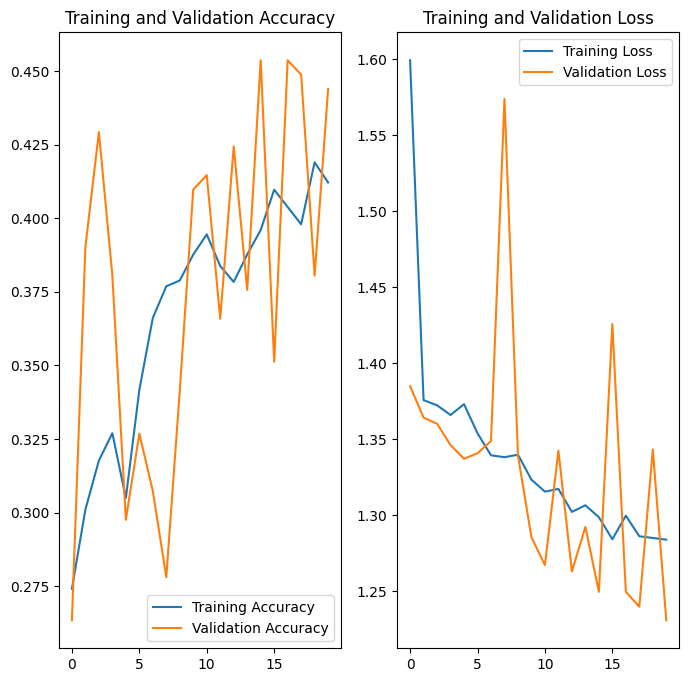

In [24]:
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']

loss = history.history['loss']
val_loss = history.history['val_loss']

epochs_range = range(epochs)

plt.figure(figsize=(8, 8))
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy')
plt.plot(epochs_range, val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.title('Training and Validation Accuracy')

plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss')
plt.plot(epochs_range, val_loss, label='Validation Loss')
plt.legend(loc='upper right')
plt.title('Training and Validation Loss')
plt.show()

## testing

In [25]:
test_ds = test_datagen.flow_from_directory(
    f'{DATASET_PATH}/test',
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='sparse'
)
test_loss, test_acc = model.evaluate(test_ds)
print(f"Test accuracy: {test_acc:.2f}")

Found 146 images belonging to 4 classes.
10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 74ms/step - accuracy: 0.3553 - loss: 1.2965
Test accuracy: 0.35
